In [37]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()))))
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), 'model')))
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), '../../src')))

In [38]:
import torch
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# TensOps library
import tensopsciml as to
from tensopsciml import TensOps

# Functions of PGNNIV example
from model.architecture.PGNNIV_architecture import PGNNIV
from model.utils.load_data import load_data
from model.utils.split_data import get_train_val_indices, train_val_split_torch_tensops
from model.utils.checkpoints import load_results

from visualizers.utils.error import relative_error_stats
from visualizers.utils.plots import plot_tensors

In [39]:
SEED = 42

np.random.seed(SEED)  
torch.manual_seed(SEED)  
GEN = torch.Generator().manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

if DEVICE.type == 'cuda':
    torch.cuda.manual_seed(SEED)

Using device: cuda


In [40]:
data_name = 'Ogden_N1000_S0_train'
model_name = 'PGNNIV_baseline'

# Paths definition
ROOT_PATH = os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), '../pgnniv'))
DATA_FOLDER_PATH = os.path.join(ROOT_PATH, 'datasets', 'train_data', 'data')
RESULTS_FOLDER_PATH = os.path.join(ROOT_PATH, 'results')

DATA_PATH = os.path.join(DATA_FOLDER_PATH, data_name) + '.pkl'
MODEL_RESULTS_PATH = os.path.join(RESULTS_FOLDER_PATH, model_name, data_name)

In [41]:
# General parameters
dataset = load_data(DATA_PATH)

dx = dataset['x_step_size']
dy = dataset['y_step_size']
D = to.Derivative(dx, dy, 0, indexing='xy').two_dimensions().to(DEVICE)

Data successfully loaded from: /home/rmunoz/Escritorio/rmunozTMELab/TensOps/nb/examples/pgnniv/datasets/train_data/data/Ogden_N1000_S0_train.pkl


In [42]:
def smooth_curve(data, window_size=5):
    window = np.ones(window_size) / window_size
    return np.convolve(data, window, mode='valid')

def cm_to_in(cm):
    return cm * 0.393701

def normalize_list(lst):
    max_testue = np.max(lst)
    return [x / max_testue for x in lst]

linewidth = 1.5  
title_fontsize = 14  
label_fontsize = 14  
legend_fontsize = 12 
tick_fontsize = 11  

# plt.rc('text', usetex=True)
plt.rc('font', family='serif')

posX = cm_to_in(10) 
posY = cm_to_in(10)
width = cm_to_in(12)
height = cm_to_in(8) 

color = [0.1, 0, 0.8]
subplot_adjust_left = cm_to_in(0.15)
subplot_adjust_bottom = cm_to_in(0.15)

# Load model

In [43]:
U_dataset = dataset['U']
F_dataset = dataset['F']
E_dataset = dataset['E']
P_dataset = dataset['P']
Tx_dataset, Ty_dataset = dataset['Tx'], dataset['Ty']

In [44]:
# Displacement field U(x, y)
U = torch.zeros(U_dataset.shape[0], 2, U_dataset.shape[1], U_dataset.shape[2], dtype=torch.float32)
U[:, 0] = torch.tensor(U_dataset[..., 0], dtype=torch.float32)
U[:, 1] = torch.tensor(U_dataset[..., 1], dtype=torch.float32)
U = TensOps(U.to(DEVICE), domain_dim=2, codomain_dim=[2], order=[1, 0], contravariant_indices=[0], covariant_indices=None)

# Gradient field FF(x, y)
F = torch.zeros(F_dataset.shape[0], 2, 2, F_dataset.shape[1]-1, F_dataset.shape[2]-1)
F[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F = TensOps(F.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# Green-Lagrange tensor EE(x, y)
E = torch.zeros(E_dataset.shape[0], 2, 2, E_dataset.shape[1]-1, E_dataset.shape[2]-1)
E[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E = TensOps(E.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# First Piola-Kirchhoff stress P(x, y). P^{ij}, order [2, 0].
P = torch.zeros(P_dataset.shape[0], 2, 2, P_dataset.shape[1]-1, P_dataset.shape[2]-1)
P[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P = TensOps(P.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[2, 0], contravariant_indices=[0, 1], covariant_indices=None)

# Boundary tractions T^i = P^{ij} N_j (full traction vectors), already
# cell-averaged and reshaped to (N, 2, Ny-1, 1) / (N, 2, 1, Nx-1) by the data
# generator.
Tx = torch.tensor(Tx_dataset, dtype=torch.float32)
Ty = torch.tensor(Ty_dataset, dtype=torch.float32)

In [45]:
# Model parameters
latent_space_predictive = 10
n_filters_explanatory = 10

# Predictive network architecture
input_shape_1 = Tx[0].shape
input_shape_2 = Ty[0].shape
predictive_layers = [50, 20, latent_space_predictive, 20, 50]
predictive_output = U.values[0].shape

# Explanatory network architecture
explanatory_input = E.values[0].shape
explanatory_layers = [50]
explanatory_output = P.values[0].shape

# Metric of the problem: Euclidean (Cartesian) g_{ij} = delta_{ij} on the
# interior grid where GradU/E/P live. Built once here as a batch-1 MetrOps and
# passed into the model, which broadcasts it to each step's batch size.
grid = E.values.shape[-2:]
metric_ = torch.eye(2, dtype=torch.float32).reshape(1, 2, 2, 1, 1).expand(1, 2, 2, *grid).clone()
metric = to.MetrOps(metric_.to(DEVICE), domain_dim=2, codomain_dim=[2, 2])

# Load validation data

In [46]:
data_name = 'Ogden_N100_S0_test_lambda102'

DATA_FOLDER_PATH = os.path.join(ROOT_PATH, 'datasets', 'test_data', 'data')
DATA_PATH = os.path.join(DATA_FOLDER_PATH, data_name) + '.pkl'
dataset = load_data(DATA_PATH)

U_dataset = dataset['U']
F_dataset = dataset['F']
E_dataset = dataset['E']
P_dataset = dataset['P']
Tx_dataset, Ty_dataset = dataset['Tx'], dataset['Ty']
lambda1, lambda2, lambda3 = dataset['lambda1'], dataset['lambda2'], dataset['lambda3']

# Displacement field U(x, y)
U = torch.zeros(U_dataset.shape[0], 2, U_dataset.shape[1], U_dataset.shape[2], dtype=torch.float32)
U[:, 0] = torch.tensor(U_dataset[..., 0], dtype=torch.float32)
U[:, 1] = torch.tensor(U_dataset[..., 1], dtype=torch.float32)
U_L102 = TensOps(U.to(DEVICE), domain_dim=2, codomain_dim=[2], order=[1, 0], contravariant_indices=[0], covariant_indices=None)

# Gradient field FF(x, y)
F = torch.zeros(F_dataset.shape[0], 2, 2, F_dataset.shape[1]-1, F_dataset.shape[2]-1)
F[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F_L102 = TensOps(F.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# Green-Lagrange tensor EE(x, y)
E = torch.zeros(E_dataset.shape[0], 2, 2, E_dataset.shape[1]-1, E_dataset.shape[2]-1)
E[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E_L102 = TensOps(E.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# First Piola-Kirchhoff stress P(x, y). P^{ij}, order [2, 0].
P = torch.zeros(P_dataset.shape[0], 2, 2, P_dataset.shape[1]-1, P_dataset.shape[2]-1)
P[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P_L102 = TensOps(P.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[2, 0], contravariant_indices=[0, 1], covariant_indices=None)

# Boundary tractions T^i = P^{ij} N_j (full traction vectors), already
# cell-averaged and reshaped to (N, 2, Ny-1, 1) / (N, 2, 1, Nx-1) by the data
# generator.
Tx_L102 = torch.tensor(Tx_dataset, dtype=torch.float32)
Ty_L102 = torch.tensor(Ty_dataset, dtype=torch.float32)

Data successfully loaded from: /home/rmunoz/Escritorio/rmunozTMELab/TensOps/nb/examples/pgnniv/datasets/test_data/data/Ogden_N100_S0_test_lambda102.pkl


In [47]:
data_name = 'Ogden_N100_S0_test_lambda105'

DATA_FOLDER_PATH = os.path.join(ROOT_PATH, 'datasets', 'test_data', 'data')
DATA_PATH = os.path.join(DATA_FOLDER_PATH, data_name) + '.pkl'
dataset = load_data(DATA_PATH)

U_dataset = dataset['U']
F_dataset = dataset['F']
E_dataset = dataset['E']
P_dataset = dataset['P']
Tx_dataset, Ty_dataset = dataset['Tx'], dataset['Ty']
lambda1, lambda2, lambda3 = dataset['lambda1'], dataset['lambda2'], dataset['lambda3']

# Displacement field U(x, y)
U = torch.zeros(U_dataset.shape[0], 2, U_dataset.shape[1], U_dataset.shape[2], dtype=torch.float32)
U[:, 0] = torch.tensor(U_dataset[..., 0], dtype=torch.float32)
U[:, 1] = torch.tensor(U_dataset[..., 1], dtype=torch.float32)
U_L105 = TensOps(U.to(DEVICE), domain_dim=2, codomain_dim=[2], order=[1, 0], contravariant_indices=[0], covariant_indices=None)

# Gradient field FF(x, y)
F = torch.zeros(F_dataset.shape[0], 2, 2, F_dataset.shape[1]-1, F_dataset.shape[2]-1)
F[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F_L105 = TensOps(F.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# Green-Lagrange tensor EE(x, y)
E = torch.zeros(E_dataset.shape[0], 2, 2, E_dataset.shape[1]-1, E_dataset.shape[2]-1)
E[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E_L105 = TensOps(E.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# First Piola-Kirchhoff stress P(x, y). P^{ij}, order [2, 0].
P = torch.zeros(P_dataset.shape[0], 2, 2, P_dataset.shape[1]-1, P_dataset.shape[2]-1)
P[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P_L105 = TensOps(P.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[2, 0], contravariant_indices=[0, 1], covariant_indices=None)

# Boundary tractions T^i = P^{ij} N_j (full traction vectors), already
# cell-averaged and reshaped to (N, 2, Ny-1, 1) / (N, 2, 1, Nx-1) by the data
# generator.
Tx_L105 = torch.tensor(Tx_dataset, dtype=torch.float32)
Ty_L105 = torch.tensor(Ty_dataset, dtype=torch.float32)

Data successfully loaded from: /home/rmunoz/Escritorio/rmunozTMELab/TensOps/nb/examples/pgnniv/datasets/test_data/data/Ogden_N100_S0_test_lambda105.pkl


In [48]:
data_name = 'Ogden_N100_S0_test_lambda108'

DATA_FOLDER_PATH = os.path.join(ROOT_PATH, 'datasets', 'test_data', 'data')
DATA_PATH = os.path.join(DATA_FOLDER_PATH, data_name) + '.pkl'
dataset = load_data(DATA_PATH)

U_dataset = dataset['U']
F_dataset = dataset['F']
E_dataset = dataset['E']
P_dataset = dataset['P']
Tx_dataset, Ty_dataset = dataset['Tx'], dataset['Ty']
lambda1, lambda2, lambda3 = dataset['lambda1'], dataset['lambda2'], dataset['lambda3']

# Displacement field U(x, y)
U = torch.zeros(U_dataset.shape[0], 2, U_dataset.shape[1], U_dataset.shape[2], dtype=torch.float32)
U[:, 0] = torch.tensor(U_dataset[..., 0], dtype=torch.float32)
U[:, 1] = torch.tensor(U_dataset[..., 1], dtype=torch.float32)
U_L108 = TensOps(U.to(DEVICE), domain_dim=2, codomain_dim=[2], order=[1, 0], contravariant_indices=[0], covariant_indices=None)

# Gradient field FF(x, y)
F = torch.zeros(F_dataset.shape[0], 2, 2, F_dataset.shape[1]-1, F_dataset.shape[2]-1)
F[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(F_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
F_L108 = TensOps(F.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# Green-Lagrange tensor EE(x, y)
E = torch.zeros(E_dataset.shape[0], 2, 2, E_dataset.shape[1]-1, E_dataset.shape[2]-1)
E[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(E_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
E_L108 = TensOps(E.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[1, 1], contravariant_indices=[0], covariant_indices=[1])

# First Piola-Kirchhoff stress P(x, y). P^{ij}, order [2, 0].
P = torch.zeros(P_dataset.shape[0], 2, 2, P_dataset.shape[1]-1, P_dataset.shape[2]-1)
P[:, 0, 0] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 0], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P[:, 1, 1] = to.m2(to.m1(TensOps(torch.tensor(P_dataset[..., 1], dtype=torch.float32).unsqueeze(1), domain_dim=2, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None))).values[:, 0]
P_L108 = TensOps(P.to(DEVICE), domain_dim=2, codomain_dim=[2, 2], order=[2, 0], contravariant_indices=[0, 1], covariant_indices=None)

# Boundary tractions T^i = P^{ij} N_j (full traction vectors), already
# cell-averaged and reshaped to (N, 2, Ny-1, 1) / (N, 2, 1, Nx-1) by the data
# generator.
Tx_L108 = torch.tensor(Tx_dataset, dtype=torch.float32)
Ty_L108 = torch.tensor(Ty_dataset, dtype=torch.float32)

Data successfully loaded from: /home/rmunoz/Escritorio/rmunozTMELab/TensOps/nb/examples/pgnniv/datasets/test_data/data/Ogden_N100_S0_test_lambda108.pkl


# Validation

In [49]:
pgnniv_model = PGNNIV(input_shape_1, input_shape_2, predictive_layers, predictive_output,
                      explanatory_input, explanatory_layers, explanatory_output,
                      n_filters_explanatory, D, metric).to(DEVICE)

optimizer = torch.optim.Adam(pgnniv_model.parameters(), lr=1e-3)
pgnniv_loaded, optimizer, lists = load_results(pgnniv_model, optimizer, MODEL_RESULTS_PATH, map_location=DEVICE)

In [50]:
E_L102_val = E_L102.values[:, :, :, 0, 0].unsqueeze(-1).unsqueeze(-1).reshape(E_L102.values.shape[0], 4, 1, 1)
P_L102_val = P_L102.values[:, :, :, 0, 0].unsqueeze(-1).unsqueeze(-1)
# The explanatory network now predicts the SECOND Piola-Kirchhoff stress
# S^{kl}, so reproduce the two steps forward() applies on top of it:
#   1) output_scale, which this direct call bypasses,
#   2) symmetrization + the pull-back P^{ij} = F^i_k S^{kj}.
S_L102_pred = (pgnniv_loaded.explanatory(E_L102_val) * pgnniv_loaded.output_scale).reshape(E_L102_val.shape[0], 2, 2)
S_L102_pred = 0.5 * (S_L102_pred + S_L102_pred.transpose(1, 2))
F_L102_pt = F_L102.values[:, :, :, 0, 0]
P_L102_pred = torch.matmul(F_L102_pt, S_L102_pred).reshape(E_L102_val.shape[0], 2, 2, 1)

E_L102_val = E_L102_val.reshape(E_L102.values.shape[0], 2, 2, 1).detach().cpu()
P_L102_val = P_L102_val.detach().cpu()
P_L102_pred = P_L102_pred.detach().cpu()

In [51]:
E_L105_val = E_L105.values[:, :, :, 0, 0].unsqueeze(-1).unsqueeze(-1).reshape(E_L105.values.shape[0], 4, 1, 1)
P_L105_val = P_L105.values[:, :, :, 0, 0].unsqueeze(-1).unsqueeze(-1)
# The explanatory network now predicts the SECOND Piola-Kirchhoff stress
# S^{kl}, so reproduce the two steps forward() applies on top of it:
#   1) output_scale, which this direct call bypasses,
#   2) symmetrization + the pull-back P^{ij} = F^i_k S^{kj}.
S_L105_pred = (pgnniv_loaded.explanatory(E_L105_val) * pgnniv_loaded.output_scale).reshape(E_L105_val.shape[0], 2, 2)
S_L105_pred = 0.5 * (S_L105_pred + S_L105_pred.transpose(1, 2))
F_L105_pt = F_L105.values[:, :, :, 0, 0]
P_L105_pred = torch.matmul(F_L105_pt, S_L105_pred).reshape(E_L105_val.shape[0], 2, 2, 1)

E_L105_val = E_L105_val.reshape(E_L105.values.shape[0], 2, 2, 1).detach().cpu()
P_L105_val = P_L105_val.detach().cpu()
P_L105_pred = P_L105_pred.detach().cpu()

In [52]:
E_L108_val = E_L108.values[:, :, :, 0, 0].unsqueeze(-1).unsqueeze(-1).reshape(E_L108.values.shape[0], 4, 1, 1)
P_L108_val = P_L108.values[:, :, :, 0, 0].unsqueeze(-1).unsqueeze(-1)
# The explanatory network now predicts the SECOND Piola-Kirchhoff stress
# S^{kl}, so reproduce the two steps forward() applies on top of it:
#   1) output_scale, which this direct call bypasses,
#   2) symmetrization + the pull-back P^{ij} = F^i_k S^{kj}.
S_L108_pred = (pgnniv_loaded.explanatory(E_L108_val) * pgnniv_loaded.output_scale).reshape(E_L108_val.shape[0], 2, 2)
S_L108_pred = 0.5 * (S_L108_pred + S_L108_pred.transpose(1, 2))
F_L108_pt = F_L108.values[:, :, :, 0, 0]
P_L108_pred = torch.matmul(F_L108_pt, S_L108_pred).reshape(E_L108_val.shape[0], 2, 2, 1)

E_L108_val = E_L108_val.reshape(E_L108.values.shape[0], 2, 2, 1).detach().cpu()
P_L108_val = P_L108_val.detach().cpu()
P_L108_pred = P_L108_pred.detach().cpu()

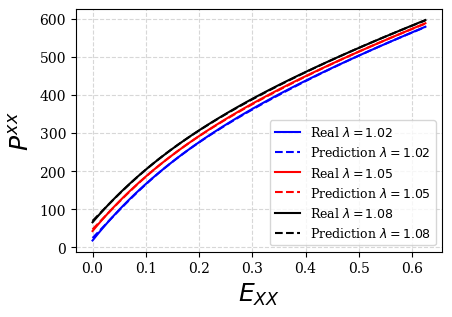

In [53]:
plt.figure(figsize=(width, height))

plt.plot(E_L102_val[:, 0, 0].flatten(), P_L102_val[:, 0, 0].flatten(), label='Real $\\lambda=1.02$', linestyle='-', color='blue')
plt.plot(E_L102_val[:, 0, 0].flatten(), P_L102_pred[:, 0, 0].flatten(), label='Prediction $\\lambda=1.02$', linestyle='--', color='blue')

plt.plot(E_L105_val[:, 0, 0].flatten(), P_L105_val[:, 0, 0].flatten(), label='Real $\\lambda=1.05$', linestyle='-', color='red')
plt.plot(E_L105_val[:, 0, 0].flatten(), P_L105_pred[:, 0, 0].flatten(), label='Prediction $\\lambda=1.05$', linestyle='--', color='red')

plt.plot(E_L108_val[:, 0, 0].flatten(), P_L108_val[:, 0, 0].flatten(), label='Real $\\lambda=1.08$', linestyle='-', color='black')
plt.plot(E_L108_val[:, 0, 0].flatten(), P_L108_pred[:, 0, 0].flatten(), label='Prediction $\\lambda=1.08$', linestyle='--', color='black')

plt.xlabel("$E_{XX}$", fontsize=18) 
# The quantity plotted is the FIRST Piola-Kirchhoff stress, not the Cauchy
# stress sigma: P^{xx}.
plt.ylabel("$P^{xx}$", fontsize=18)
plt.legend(fontsize=legend_fontsize-3)
plt.grid(True, linestyle="--", alpha=0.5)

# Automatic, centred axis limits: fit the plotted curves and leave a 5% margin
# on every side so the family of curves sits centred in the axes.
x_data = np.concatenate([E_L102_val[:, 0, 0].flatten().numpy(),
                         E_L105_val[:, 0, 0].flatten().numpy(),
                         E_L108_val[:, 0, 0].flatten().numpy()])
y_data = np.concatenate([P_L102_val[:, 0, 0].flatten().numpy(), P_L102_pred[:, 0, 0].flatten().numpy(),
                         P_L105_val[:, 0, 0].flatten().numpy(), P_L105_pred[:, 0, 0].flatten().numpy(),
                         P_L108_val[:, 0, 0].flatten().numpy(), P_L108_pred[:, 0, 0].flatten().numpy()])
x_margin = 0.05 * (x_data.max() - x_data.min())
y_margin = 0.05 * (y_data.max() - y_data.min())

plt.xlim(x_data.min() - x_margin, x_data.max() + x_margin)
plt.ylim(y_data.min() - y_margin, y_data.max() + y_margin)

plt.show()

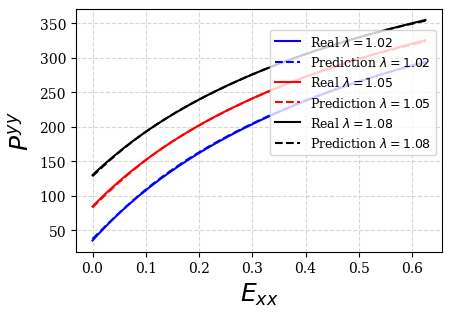

In [54]:
plt.figure(figsize=(width, height))
plt.plot(E_L102_val[:, 0, 0].flatten(), P_L102_val[:, 1, 1].flatten(), label='Real $\\lambda=1.02$', linestyle='-', color='blue')
plt.plot(E_L102_val[:, 0, 0].flatten(), P_L102_pred[:, 1, 1].flatten(), label='Prediction $\\lambda=1.02$', linestyle='--', color='blue')

plt.plot(E_L105_val[:, 0, 0].flatten(), P_L105_val[:, 1, 1].flatten(), label='Real $\\lambda=1.05$', linestyle='-', color='red')
plt.plot(E_L105_val[:, 0, 0].flatten(), P_L105_pred[:, 1, 1].flatten(), label='Prediction $\\lambda=1.05$', linestyle='--', color='red')

plt.plot(E_L108_val[:, 0, 0].flatten(), P_L108_val[:, 1, 1].flatten(), label='Real $\\lambda=1.08$', linestyle='-', color='black')
plt.plot(E_L108_val[:, 0, 0].flatten(), P_L108_pred[:, 1, 1].flatten(), label='Prediction $\\lambda=1.08$', linestyle='--', color='black')

plt.xlabel("$E_{xx}$", fontsize=18)
# As above: this is the first Piola-Kirchhoff stress P^{yy}, not sigma_yy.
plt.ylabel("$P^{yy}$", fontsize=18)
plt.legend(loc='upper right', bbox_to_anchor=(1, 0.94), fontsize=legend_fontsize-3)
plt.grid(True, linestyle="--", alpha=0.5)

# Automatic, centred axis limits: fit the plotted curves and leave a 5% margin
# on every side so the family of curves sits centred in the axes.
x_data = np.concatenate([E_L102_val[:, 0, 0].flatten().numpy(),
                         E_L105_val[:, 0, 0].flatten().numpy(),
                         E_L108_val[:, 0, 0].flatten().numpy()])
y_data = np.concatenate([P_L102_val[:, 1, 1].flatten().numpy(), P_L102_pred[:, 1, 1].flatten().numpy(),
                         P_L105_val[:, 1, 1].flatten().numpy(), P_L105_pred[:, 1, 1].flatten().numpy(),
                         P_L108_val[:, 1, 1].flatten().numpy(), P_L108_pred[:, 1, 1].flatten().numpy()])
x_margin = 0.05 * (x_data.max() - x_data.min())
y_margin = 0.05 * (y_data.max() - y_data.min())

plt.xlim(x_data.min() - x_margin, x_data.max() + x_margin)
plt.ylim(y_data.min() - y_margin, y_data.max() + y_margin)

plt.show()